In [3]:
import os
import random
import logging
import json
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter
import uproot
import awkward as ak
import joblib

# ML & Sklearn
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# TensorFlow & GPU setup
os.environ["XLA_FLAGS"] = "--xla_gpu_cuda_data_dir=/home/jlai/.local/share/mamba/envs/tf-gpu"
# Silence the oneDNN warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# wandb
import wandb
from wandb.integration.keras import WandbMetricsLogger

# Config (Assuming bdt_config.py is in your directory)
from bdt_config import Vars, Vars2, Vars3, Vars_drop

# Plot Defaults
mpl.rcParams['figure.figsize'] = 12.0, 8.0
mpl.rcParams['font.size'] = 14.0
sns.set(style="whitegrid")

In [32]:
# Load Data
path = '/home/jlai/dark_photon/code/ML_saving_all.csv'
df = pd.read_csv(path)

Vars2 = [
    "VertexBDTScore", "dmet", "dphi_jj", "dphi_met_phterm", 
    "dphi_met_jetterm", "met", "metsig", "balance", "ph_eta", 
    "ph_pt", "event",  "weights",  "label", "process"
]
Vars3 = []
Vars_drop = ['event', 'weights', 'label', 'process', 'abs_weights']

# === Data Preparation ===
df_Vars2 = df[Vars2].copy()  
df_Vars3 = df[Vars3].copy()  

# Handle inversions safely
df_Vars3.replace(-999, np.nan, inplace=True)
df_Vars3_inverted = 1 / df_Vars3.replace({0: np.nan})  

df_ml_input = pd.concat([df_Vars2, df_Vars3_inverted], axis=1)
df_ml_input.replace(-999, np.nan, inplace=True)

# Weight normalization
df_ml_input["abs_weights"] = df_ml_input["weights"].abs()
sum_weights_signal = df_ml_input[df_ml_input.label == 1].abs_weights.sum()
sum_weights_bkg = df_ml_input[df_ml_input.label == 0].abs_weights.sum()

mask_sig = df_ml_input.label == 1
df_ml_input.loc[mask_sig, 'abs_weights'] = df_ml_input.loc[mask_sig, 'abs_weights'] * (sum_weights_bkg / sum_weights_signal)

print(f"Signal sum weight after: {df_ml_input[mask_sig].abs_weights.sum():.2f} | Bkg sum weight: {df_ml_input[~mask_sig].abs_weights.sum():.2f}")
print("Number of nan in each variable: ")
print(df_ml_input.isna().sum())

# === Feature Engineering ===
X = df_ml_input.drop(Vars_drop, axis=1)
y = df_ml_input['label']
weights = df_ml_input['abs_weights']

# Flag NaNs (
non_zero_nan_keys = X.columns[X.isna().sum() > 0]
for key in non_zero_nan_keys:
    X[key+"_is_nan"] = X[key].isnull().astype(int)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = np.nan_to_num(X_scaled, nan=0.0) 

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X_scaled, y, weights, test_size=0.3, stratify=y, random_state=42
)

Signal sum weight after: 306315.02 | Bkg sum weight: 306315.02
Number of nan in each variable: 
VertexBDTScore            0
dmet                      0
dphi_jj             2190771
dphi_met_phterm           0
dphi_met_jetterm     208959
met                       0
metsig                    0
balance              318442
ph_eta                    0
ph_pt                     0
event                     0
weights                   0
label                     0
process                   0
abs_weights               0
dtype: int64


In [ ]:
# === W&B Sweep Configuration ===

# --- Bottleneck Architecture ---
sweep_config = {
    'method': 'bayes',
    'metric': {
        'name': 'final_val_roc_auc',
        'goal': 'maximize'
    },
    'parameters': {
        'lr': {
            'distribution': 'log_uniform_values',
            # Shifted up to handle the massive batch sizes
            'min': 1e-5, 
            'max': 2e-2  
        },
        'batch_size': {
            'values': [1024, 2048, 4096]
        },
        'dropout': {
            'distribution': 'uniform',
            # Widened to allow heavier regularization if the model overfits
            'min': 0.1,  
            'max': 0.5   
        },
        # Tapered "funnel" architecture to prevent memorization
        'layer_1': {'values': [256, 512, 768, 1024]}, 
        'layer_2': {'values': [64, 128, 256, 512]},
        'layer_3': {'values': [32, 64, 128, 256]},
        # Including 0 allows the sweep to test 3-layer and 4-layer architectures!
        'layer_4': {'values': [0, 32, 64, 128]},  
        'layer_5': {'values': [0, 16, 32, 64]},
        'epochs': {'value': 50}
    }
}

'''
# --- Inverted Bottleneck Architecture
sweep_config = {
    'method': 'bayes',
    'metric': {
        'name': 'final_val_roc_auc',
        'goal': 'maximize'
    },
    'parameters': {
        'lr': {
            'distribution': 'log_uniform_values',
            'min': 1e-5,
            'max': 3e-2
        },
        'batch_size': {
            'values': [1024, 2048, 4096]
        },
        'dropout': {
            'distribution': 'uniform',
            'min': 0.05,
            'max': 0.25
        },
        'layer_1': {'values': [64, 128, 192, 256]},
        'layer_2': {'values': [128, 192, 256, 384, 512]},
        'layer_3': {'values': [512, 768, 1024, 1536, 2048]},
        'layer_4': {'values': [128, 256, 384, 512]},
        'layer_5': {'values': [32, 64, 96, 128]},
        'epochs': {'value': 50}
    }
}
'''

def compute_significance(df, score_column="nn_scores", cut=0.01):
    sig = df[(df["label"] == 1) & (df[score_column] >= cut)]["weights"].sum()
    bkg = df[(df["label"] == 0) & (df[score_column] >= cut)]["weights"].sum()
    return sig / np.sqrt(bkg) if bkg > 0 else 0, sig/df[(df["label"] == 1)]["weights"].sum()
    
# === Sweep Training Function ===
def train():
    # Initialize a new wandb run
    wandb.init()
    config = wandb.config

    # 1. Build the Dataset Pipeline dynamically using the swept batch size
    train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train, w_train))
    train_dataset = (
        train_dataset
        .shuffle(buffer_size=len(X_train))
        .batch(config.batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )

    test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test, w_test))
    test_dataset = (
        test_dataset
        .batch(config.batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )

    # 2. Build the DNN
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],)))
    
    model.add(Dense(config.layer_1, activation='relu'))
    model.add(Dropout(config.dropout))
    
    model.add(Dense(config.layer_2, activation='relu'))
    model.add(Dropout(config.dropout))
    
    model.add(Dense(config.layer_3, activation='relu'))
    model.add(Dropout(config.dropout))
    
    # Only add these layers if the sweep didn't choose 0!
    if config.layer_4 > 0:
        model.add(Dense(config.layer_4, activation='relu'))
        model.add(Dropout(config.dropout))
        
    if config.layer_5 > 0:
        model.add(Dense(config.layer_5, activation='relu'))
        model.add(Dropout(config.dropout))
        
    model.add(Dense(1, activation='sigmoid'))

    # 3. Compile
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=config.lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc")],
        weighted_metrics=[tf.keras.metrics.AUC(name="weighted_auc")]
    )

    early_stop = EarlyStopping(
        monitor="val_weighted_auc",
        patience=5,
        mode="max",
        restore_best_weights=True
    )

    # 4. Train
    model.fit(
        train_dataset,
        validation_data=test_dataset,
        epochs=config.epochs,
        callbacks=[early_stop, WandbMetricsLogger()],
        verbose=1
    )

    # 5. Evaluate and Log Final Metrics
    # Using the test_dataset for prediction prevents memory exhaustion
    probs = model.predict(test_dataset).ravel()
    auc = roc_auc_score(y_test, probs, sample_weight=w_test)
    wandb.log({"final_val_roc_auc": auc})

    X_scaled_array = np.asarray(X_scaled)
    nn_scores = model.predict(X_scaled_array, batch_size=config.batch_size).flatten()  # shape: (n_samples,)
    
    df_tmp = df_ml_input.copy()
    df_tmp['nn_scores'] = nn_scores

    best_significance, best_acceptance, best_cut = 0, 0, 0
    for cut in np.arange(0, 1, 0.01):
        sig, acc = compute_significance(df_tmp, score_column="nn_scores", cut=cut)
        if sig > best_significance:
            best_significance = sig
            best_acceptance = acc
            best_cut = cut

    wandb.log({
        "Max S/sqrt(B)": best_significance,
        "Acceptance": best_acceptance,
        "nnScore cut": best_cut
    })
    print("best significance: ", best_significance, " best acceptance: ", best_acceptance, " nnScore cut: ", best_cut)

# === Initialize and Run Sweep ===
# Start the sweep
sweep_id = wandb.sweep(sweep_config, project="Dark_ph_DNN_Sweep_4_27_bottleneck")

# Run 50 times
wandb.agent(sweep_id, function=train, count=70)

Create sweep with ID: kxvgzspv
Sweep URL: https://wandb.ai/dlai211/Dark_ph_DNN_Sweep_4_27_bottleneck/sweeps/kxvgzspv


wandb: Agent Starting Run: e85k98cf with config:
wandb: 	batch_size: 4096
wandb: 	dropout: 0.47105512176152686
wandb: 	epochs: 50
wandb: 	layer_1: 1024
wandb: 	layer_2: 128
wandb: 	layer_3: 64
wandb: 	layer_4: 128
wandb: 	layer_5: 64
wandb: 	lr: 0.0026438707887017614
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/jlai/.netrc.


wandb: 
wandb: 🚀 View run glorious-sweep-1 at: https://wandb.ai/dlai211/Dark_ph_DNN_Sweep_4_27_bottleneck/runs/ickzp1bt
wandb: Find logs at: wandb/run-20260427_203417-ickzp1bt/logs


Epoch 1/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - auc: 0.9145 - loss: 0.0376 - weighted_auc: 0.9267 - val_auc: 0.9368 - val_loss: 0.0309 - val_weighted_auc: 0.9473
Epoch 2/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - auc: 0.9312 - loss: 0.0335 - weighted_auc: 0.9363 - val_auc: 0.9419 - val_loss: 0.0318 - val_weighted_auc: 0.9483
Epoch 3/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - auc: 0.9312 - loss: 0.0334 - weighted_auc: 0.9366 - val_auc: 0.9403 - val_loss: 0.0304 - val_weighted_auc: 0.9501
Epoch 4/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - auc: 0.9345 - loss: 0.0326 - weighted_auc: 0.9385 - val_auc: 0.9487 - val_loss: 0.0318 - val_weighted_auc: 0.9509
Epoch 5/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - auc: 0.9366 - loss: 0.0323 - weighted_auc: 0.9393 - val_auc: 0.9447 - val_loss: 0.0298 - val_weighted_auc: 0.9507
Epoch 6/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - auc: 0.9374 - loss: 0.0328 - weighted_auc: 0.9380 - val_auc: 0.9472 - val_loss: 0.0310 - val_w

Acceptance,▁
Max S/sqrt(B),▁
epoch/auc,▁▆▆▇██▇▇▇▇▇█
epoch/epoch,▁▂▂▃▄▄▅▅▆▇▇█
epoch/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁
epoch/loss,█▃▃▂▁▂▂▂▂▂▂▁
epoch/val_auc,▁▄▃▇▅▇▆▆█▅▅▅
epoch/val_loss,▅█▃█▁▅▂▄▅▆▁▆
epoch/val_weighted_auc,▁▃▆▇▇▇█▅▇▆▅▇
epoch/weighted_auc,▁▆▇██▇▇▇▇▇▆█
+2,...


...

wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: t1sx0i4b with config:
wandb: 	batch_size: 2048
wandb: 	dropout: 0.1665557918714755
wandb: 	epochs: 50
wandb: 	layer_1: 1024
wandb: 	layer_2: 256
wandb: 	layer_3: 64
wandb: 	layer_4: 32
wandb: 	layer_5: 32
wandb: 	lr: 9.519719596558248e-05
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/jlai/.netrc.


Epoch 1/50
1963/1963 ━━━━━━━━━━━━━━━━━━━━ 28s 9ms/step - auc: 0.9051 - loss: 0.0359 - weighted_auc: 0.9259 - val_auc: 0.9337 - val_loss: 0.0311 - val_weighted_auc: 0.9451
Epoch 2/50
1963/1963 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - auc: 0.9331 - loss: 0.0313 - weighted_auc: 0.9410 - val_auc: 0.9439 - val_loss: 0.0300 - val_weighted_auc: 0.9496
Epoch 3/50
1963/1963 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - auc: 0.9418 - loss: 0.0300 - weighted_auc: 0.9452 - val_auc: 0.9479 - val_loss: 0.0289 - val_weighted_auc: 0.9519
Epoch 4/50
1963/1963 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - auc: 0.9452 - loss: 0.0293 - weighted_auc: 0.9479 - val_auc: 0.9464 - val_loss: 0.0292 - val_weighted_auc: 0.9522
Epoch 5/50
1963/1963 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - auc: 0.9463 - loss: 0.0290 - weighted_auc: 0.9488 - val_auc: 0.9518 - val_loss: 0.0284 - val_weighted_auc: 0.9536
Epoch 6/50
1963/1963 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - auc: 0.9476 - loss: 0.0287 - weighted_auc: 0.9499 - val_auc: 0.9497 - val_loss: 0.0284 -

Acceptance,▁
Max S/sqrt(B),▁
epoch/auc,▁▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇█▇███████████
epoch/epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇███
epoch/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/loss,█▅▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
epoch/val_auc,▁▄▅▄▆▅▆▆▆▆▆▆▆▆▇▇▆▆█▇▇████▇█████████
epoch/val_loss,█▆▅▅▄▄▃▄▃▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁▂▁▁▁▁▁▁▁▂▁▁
epoch/val_weighted_auc,▁▃▄▄▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇█▇▇▇█████████
epoch/weighted_auc,▁▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇███████████
+2,...


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: nyd2p0r9 with config:
wandb: 	batch_size: 2048
wandb: 	dropout: 0.49493916575285735
wandb: 	epochs: 50
wandb: 	layer_1: 256
wandb: 	layer_2: 512
wandb: 	layer_3: 256
wandb: 	layer_4: 64
wandb: 	layer_5: 16
wandb: 	lr: 9.485821578924084e-05
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/jlai/.netrc.


Epoch 1/50


/app/.pixi/envs/ml/lib/python3.12/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - auc: 0.9298 - loss: 0.0319 - weighted_auc: 0.9400 - val_auc: 0.9494 - val_loss: 0.0293 - val_weighted_auc: 0.9508
Epoch 2/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - auc: 0.9456 - loss: 0.0290 - weighted_auc: 0.9491 - val_auc: 0.9517 - val_loss: 0.0288 - val_weighted_auc: 0.9531
Epoch 3/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - auc: 0.9478 - loss: 0.0284 - weighted_auc: 0.9509 - val_auc: 0.9529 - val_loss: 0.0286 - val_weighted_auc: 0.9538
Epoch 4/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - auc: 0.9494 - loss: 0.0282 - weighted_auc: 0.9519 - val_auc: 0.9509 - val_loss: 0.0291 - val_weighted_auc: 0.9535
Epoch 5/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - auc: 0.9501 - loss: 0.0278 - weighted_auc: 0.9534 - val_auc: 0.9550 - val_loss: 0.0284 - val_weighted_auc: 0.9552
Epoch 6/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - auc: 0.9513 - loss: 0.0275 - weighted_auc: 0.9544 - val_auc: 0.9534 - val_loss: 0.0282 - val_weighted_auc

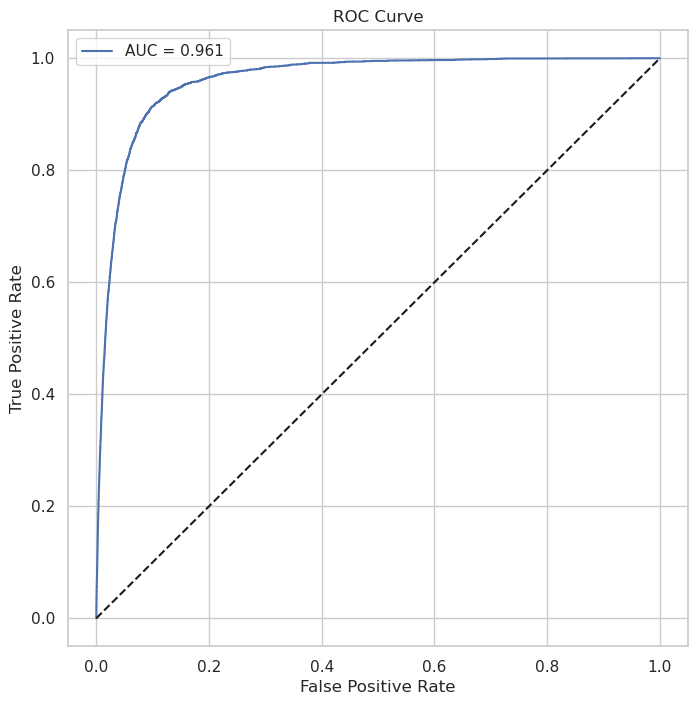

epoch/auc,▁▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇██▇██▇███
epoch/epoch,▁▁▂▂▂▂▃▃▃▄▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
epoch/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/loss,█▅▅▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁
epoch/val_auc,▁▂▃▂▄▃▄▂▆▄▄▆▆▅▅▆▇▆█▇▇█▇▆▆▇
epoch/val_loss,█▇▆█▆▅▄▆▃▅▃▃▂▃▃▃▂▂▂▂▃▃▂▁▃▃
epoch/val_weighted_auc,▁▃▃▃▄▄▅▆▆▆▆▆▇▇▆▇▇▇█▇██▇█▇▇
epoch/weighted_auc,▁▄▄▅▅▅▆▆▆▆▇▆▇▇▇▇▇▇▇███████
final_val_roc_auc,▁
epoch/auc,0.96021
epoch/epoch,25


In [20]:
wandb.init(project="tf-dnn-weighted-classifier", config={
    "epochs": 50,
    "batch_size": 4096,
    "lr": 0.0001148,
    "hidden_layers": [1024, 128, 128, 32, 64],
    "dropout": 0.1129,
    "early_stopping_patience": 5
})
config = wandb.config


model = Sequential()
model.add(Dense(config.hidden_layers[0], activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dropout(config.dropout))
for h in config.hidden_layers[1:]:
    model.add(Dense(h, activation='relu'))
    model.add(Dropout(config.dropout))
model.add(Dense(1, activation='sigmoid'))

optimizer = tf.keras.optimizers.Adam(learning_rate=config.lr)
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="auc", curve="ROC", from_logits=False)
    ],
    weighted_metrics=[
        tf.keras.metrics.AUC(name="weighted_auc", curve="ROC", from_logits=False)
    ]
)


early_stop = EarlyStopping(monitor='val_weighted_auc', patience=config.early_stopping_patience,
                           mode='max', restore_best_weights=True, verbose=1)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test, w_test),
    sample_weight=w_train,
    epochs=config.epochs,
    batch_size=config.batch_size,
    callbacks=[early_stop, WandbMetricsLogger()],
    verbose=1
)

probs = model.predict(X_test).ravel()
auc = roc_auc_score(y_test, probs, sample_weight=w_test)
fpr, tpr, _ = roc_curve(y_test, probs, sample_weight=w_test)

wandb.log({"final_val_roc_auc": auc})

plt.figure(figsize=(8, 8))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
wandb.log({"ROC Curve": wandb.Image(plt)})
plt.show()

wandb.finish()

In [33]:
X_scaled_array = np.asarray(X_scaled)
nn_scores = model.predict(X_scaled_array, batch_size=4096).flatten()  # shape: (n_samples,)

df_ml_input['MLNNScore'] = nn_scores

1417/1417 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


In [35]:
# save the dataframe to csv file
df_ml_input.to_csv("/home/jlai/dark_photon/code/nn_output.csv", index=False)

In [34]:
def compute_significance(df, cut=0.5):
    s = df[(df["label"] == 1) & (df["MLNNScore"] >= cut)]["weights"].sum()
    b = df[(df["label"] == 0) & (df["MLNNScore"] >= cut)]["weights"].sum()
    return s / np.sqrt(b) if b > 0 else 0, s/df[(df['label'] == 1)]['weights'].sum()

max_sig, acceptance = max(compute_significance(df_ml_input, cut) for cut in np.arange(0.0, 1, 0.01))
print(f"Max S/√B: {max_sig:.3f}, Acceptance: {acceptance*100} %")


Max S/√B: 3.799, Acceptance: 55.49380371282434 %


Saved plot to significance_nn_scores_lowercut.png


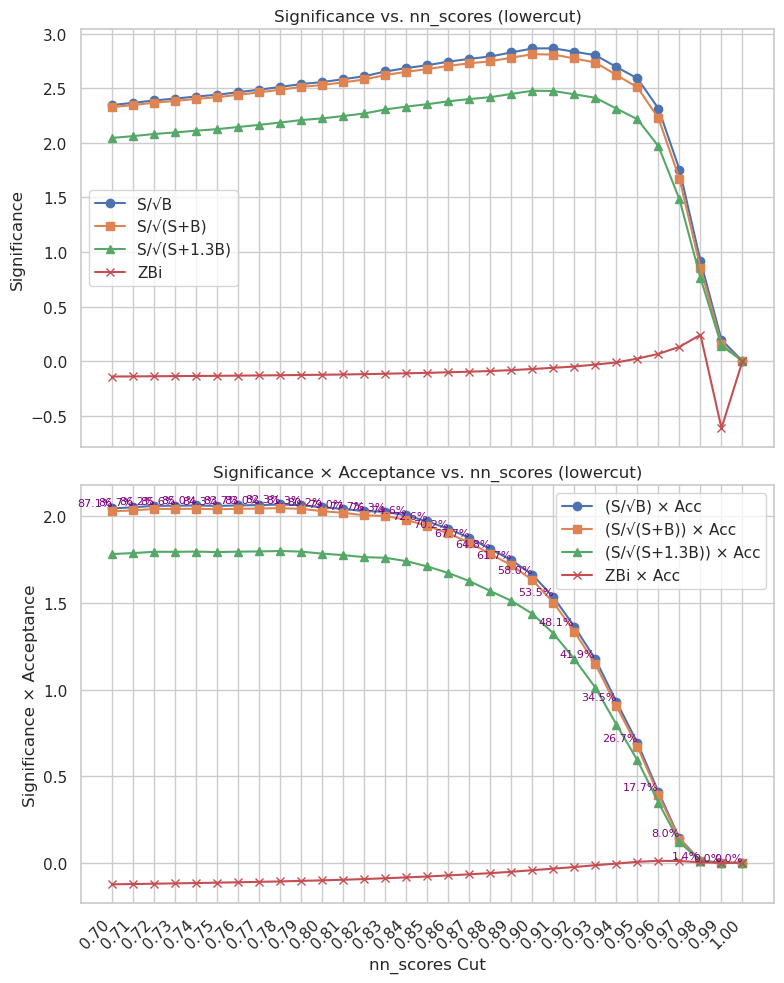

In [25]:
import sys
sys.path.append('/home/jlai/dark_photon/code/config')
from plot_config import getWeight, zbi, sample_dict, getVarDict
import matplotlib.ticker as ticker

def binomial_significance(s, b):
    return s / np.sqrt(b) if b > 0 else 0

def s_over_sb(s, b):
    return s / np.sqrt(s + b) if (s + b) > 0 else 0

def s_over_s1p3b(s, b):
    return s / np.sqrt(s + 1.3 * b) if (s + 1.3 * b) > 0 else 0

def scan_significance(df, cut_var="nn_scores", cut_type="lowercut", cuts=np.arange(0, 0.71, 0.01)):
    sig_sqrtb = []
    sig_sqrt_sb = []
    sig_sqrt_s1p3b = []
    sig_zbi = []

    sigacc_sqrtb = []
    sigacc_sqrt_sb = []
    sigacc_sqrt_s1p3b = []
    sigacc_zbi = []

    acc_values = []

    df_sig = df[df["label"] == 1]
    df_bkg = df[df["label"] == 0]
    total_sig_weight = df_sig["weights"].sum()

    for cut in cuts:
        if cut_type == "lowercut":
            sig_cut = df_sig[df_sig[cut_var] >= cut]
            bkg_cut = df_bkg[df_bkg[cut_var] >= cut]
        elif cut_type == "uppercut":
            sig_cut = df_sig[df_sig[cut_var] <= cut]
            bkg_cut = df_bkg[df_bkg[cut_var] <= cut]
        else:
            raise ValueError("Invalid cut type")

        s = sig_cut["weights"].sum()
        b = bkg_cut["weights"].sum()
        acceptance = s / total_sig_weight if total_sig_weight > 0 else 0

        # Compute significance
        sig1 = binomial_significance(s, b)
        sig2 = s_over_sb(s, b)
        sig3 = s_over_s1p3b(s, b)
        sig4 = zbi(s, b)

        sig_sqrtb.append(sig1)
        sig_sqrt_sb.append(sig2)
        sig_sqrt_s1p3b.append(sig3)
        sig_zbi.append(sig4)

        sigacc_sqrtb.append(sig1 * acceptance)
        sigacc_sqrt_sb.append(sig2 * acceptance)
        sigacc_sqrt_s1p3b.append(sig3 * acceptance)
        sigacc_zbi.append(sig4 * acceptance)

        acc_values.append(acceptance * 100)

    return cuts, acc_values, sig_sqrtb, sig_sqrt_sb, sig_sqrt_s1p3b, sig_zbi, \
           sigacc_sqrtb, sigacc_sqrt_sb, sigacc_sqrt_s1p3b, sigacc_zbi


def plot_significance(cuts, acc, sig1, sig2, sig3, sig4,
                      sigacc1, sigacc2, sigacc3, sigacc4,
                      cut_var, cut_type, save_path):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10), sharex=True)

    # Plot Significance
    ax1.plot(cuts, sig1, marker='o', label='S/√B')
    ax1.plot(cuts, sig2, marker='s', label='S/√(S+B)')
    ax1.plot(cuts, sig3, marker='^', label='S/√(S+1.3B)')
    ax1.plot(cuts, sig4, marker='x', label='ZBi')

    ax1.set_ylabel('Significance')
    ax1.set_title(f'Significance vs. {cut_var} ({cut_type})')
    ax1.grid(True)
    ax1.legend()

    # Plot Significance × Acceptance
    ax2.plot(cuts, sigacc1, marker='o', label='(S/√B) × Acc')
    ax2.plot(cuts, sigacc2, marker='s', label='(S/√(S+B)) × Acc')
    ax2.plot(cuts, sigacc3, marker='^', label='(S/√(S+1.3B)) × Acc')
    ax2.plot(cuts, sigacc4, marker='x', label='ZBi × Acc')

    for i, txt in enumerate(acc):
        ax2.text(cuts[i], sigacc1[i], f'{txt:.1f}%', fontsize=8, color='purple', ha='right', va='bottom')

    ax2.set_xlabel(f'{cut_var} Cut')
    ax2.set_ylabel('Significance × Acceptance')
    ax2.set_title(f'Significance × Acceptance vs. {cut_var} ({cut_type})')
    ax2.grid(True)
    ax2.legend()
    ax2.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax2.set_xticks(cuts)
    ax2.set_xticklabels(cuts, rotation=45, ha='right')

    plt.gca().xaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    plt.tight_layout()
    plt.savefig(save_path)
    print(f"Saved plot to {save_path}")
    plt.show()


cut_var = "nn_scores"
cut_type = "lowercut"
cut_values = np.arange(0.7, 1, 0.01)

(cuts, acc, sig1, sig2, sig3, sig4,
 sigacc1, sigacc2, sigacc3, sigacc4) = scan_significance(df_ml_input, cut_var, cut_type, cut_values)

plot_significance(
    cuts, acc, sig1, sig2, sig3, sig4,
    sigacc1, sigacc2, sigacc3, sigacc4,
    cut_var=cut_var,
    cut_type=cut_type,
    save_path=f"significance_{cut_var}_{cut_type}.png"
)
